In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

clean_path = r"C:\Users\himsh\OneDrive\Desktop\talent-funnel-bottleneck-analytics\data\clean_hiring_tracker.csv"
df = pd.read_csv(clean_path)

print("Total rows:", len(df))
df.head()

Total rows: 3163


,s_no,name,phone_number,source,role,target_market,contacted_by,applied_date,contacted_date,current_status,remarks
0,1,Neha Gupta,7107420369,LinkedIn,HR Recruiter,Noida,Chetan,2026-09-01,2026-09-01,Rejected in HR Interview,Chetan: [01-Sep] bad communication skills
1,2,Komal Joshi,7373399426,Naukri,Sales Executive,Gurgaon,Chetan,2026-08-05,2026-08-05,Rejected in Final Interview,Chetan: [05-Aug] weak closing skills in final ...
2,3,Abhishek Tiwari,9585650756,Indeed,Pre-Sales,Gurgaon,Sameer,2026-10-11,2026-10-11,Offer Declined,Sameer: [11-Oct] family not agreeing for reloc...
3,4,Komal Joshi,8801823908,Apna,Sales Executive,Gurgaon,Chetan,2026-09-27,2026-09-28,Not Looking for Job,Chetan: [28-Sep] already joined somewhere
4,5,Riya Rana,8461364854,LinkedIn,Pre-Sales,Gurgaon,Sameer,2026-08-20,2026-08-20,Not Interested,Sameer: [20-Aug] wants WFH / desk job only


# EDA and Analysis

In [2]:
# Step 1: Map raw candidate statuses into sequential hiring funnel stages
# Purpose: Identify exact candidate volume and drop-off percentage at each stage of the pipeline

stage_map = {
    'Not Looking for Job': '1. Screened / Cold',
    'Not Interested': '1. Screened / Cold',
    'Not Suitable': '1. Screened / Cold',
    'F2F Scheduled - No Show': '2. F2F Scheduled(Not appeared)',
    'Rejected in HR Interview': '4. HR Round',
    'Rejected in Final Interview': '5. Final Round',
    'Shortlisted': '6. Shortlisted / Offered',
    'Offer Declined': '6. Shortlisted / Offered',
    'Joined': '7. Joined'
}

df['funnel_stage'] = df['current_status'].map(stage_map)

funnel_summary = df['funnel_stage'].value_counts()

# Add F2F Appeared row right below F2F Scheduled(Not appeared)
f2f_stages = ['4. HR Round', '5. Final Round', '6. Shortlisted / Offered', '7. Joined']
funnel_summary['3 F2F Appeared (Total)'] = funnel_summary[f2f_stages].sum()

funnel_summary = funnel_summary.sort_index()
funnel_pct = (funnel_summary / len(df) * 100).round(2)

pd.DataFrame({'Candidates': funnel_summary, 'Percentage (%)': funnel_pct})

,Candidates,Percentage (%)
funnel_stage,,
1. Screened / Cold,1808,57.16
2. F2F Scheduled(Not appeared),360,11.38
3 F2F Appeared (Total),995,31.46
4. HR Round,484,15.30
5. Final Round,255,8.06
6. Shortlisted / Offered,219,6.92
7. Joined,37,1.17


In [3]:
# Step 2: Filter ONLY Rejected / Not Suitable candidates and extract exact rejection reasons from remarks
# Purpose: Identify the top root causes behind candidate rejections

def get_rejection_reason(remark):
    latest_note = str(remark).split('|')[-1].lower()
    
    if any(k in latest_note for k in ['no exp', 'fresher', 'real estate experience', 'bpo', 'overage', 'irrelevant']):
        return 'No Real Estate Exp / Irrelevant'
    elif any(k in latest_note for k in ['communication', 'confidence', 'attitude', 'closing', 'target clarity', 'dubai market']):
        return 'Skill / Communication Gap'
    elif any(k in latest_note for k in ['salary', 'budget', 'counter offer', 'fixed']):
        return 'Salary Mismatch'
    elif any(k in latest_note for k in ['wfh', 'location', 'relocation', 'not interested in real estate']):
        return 'Location / Role Mismatch'
    else:
        return 'Other'

# Apply only on Rejected / Not Suitable rows (keep others as None/NaN)
rejected_mask = df['current_status'].str.contains('Rejected|Not Suitable', case=False, na=False)
df.loc[rejected_mask, 'rejection_reason'] = df.loc[rejected_mask, 'remarks'].apply(get_rejection_reason)

# Summary table of ONLY Rejection Reasons
rej_summary = df['rejection_reason'].value_counts()
rej_pct = (rej_summary / rej_summary.sum() * 100).round(2)

print(f"Total Rejected / Not Suitable Candidates: {rej_summary.sum()}\n")
pd.DataFrame({'Rejected Count': rej_summary, 'Share (%)': rej_pct})

Total Rejected / Not Suitable Candidates: 1213



,Rejected Count,Share (%)
rejection_reason,,
Skill / Communication Gap,634,52.27
No Real Estate Exp / Irrelevant,474,39.08
Salary Mismatch,105,8.66


In [4]:
# Step 3: Analyze Call Response Delay (SLA) vs. F2F Appearance & Joining Conversion
# Purpose: Measure how recruiter response time impacts candidate show-up and hiring rates

df['applied_date'] = pd.to_datetime(df['applied_date'])
df['contacted_date'] = pd.to_datetime(df['contacted_date'])
df['call_delay_days'] = (df['contacted_date'] - df['applied_date']).dt.days

# Group call delay into practical SLA buckets
def sla_bucket(days):
    if days <= 1:
        return '1. Same / Next Day (0-1d)'
    elif days <= 3:
        return '2. Moderate Delay (2-3d)'
    else:
        return '3. High Delay (4+ days)'

df['sla_bucket'] = df['call_delay_days'].apply(sla_bucket)

# Match directly using current_status so stage naming differences never break the count
f2f_statuses = ['Rejected in HR Interview', 'Rejected in Final Interview', 'Shortlisted', 'Offer Declined', 'Joined']
df['is_f2f_appeared'] = df['current_status'].isin(f2f_statuses)
df['is_joined'] = df['current_status'] == 'Joined'

sla_summary = df.groupby('sla_bucket').agg(
    Total_Leads=('s_no', 'count'),
    F2F_Appeared=('is_f2f_appeared', 'sum'),
    Joined=('is_joined', 'sum')
)

sla_summary['F2F_Rate (%)'] = (sla_summary['F2F_Appeared'] / sla_summary['Total_Leads'] * 100).round(2)
sla_summary['Join_Rate (%)'] = (sla_summary['Joined'] / sla_summary['Total_Leads'] * 100).round(2)

sla_summary

,Total_Leads,F2F_Appeared,Joined,F2F_Rate (%),Join_Rate (%)
sla_bucket,,,,,
1. Same / Next Day (0-1d),2101,670,25,31.89,1.19
2. Moderate Delay (2-3d),476,143,4,30.04,0.84
3. High Delay (4+ days),586,182,8,31.06,1.37


In [5]:
# Step 4: Evaluate Sourcing Channel Quality & Conversion ROI
# Purpose: Compare lead volume vs. actual F2F show-ups and hires across portals

source_summary = df.groupby('source').agg(
    Total_Leads=('s_no', 'count'),
    F2F_Appeared=('is_f2f_appeared', 'sum'),
    Joined=('is_joined', 'sum')
)

source_summary['F2F_Rate (%)'] = (source_summary['F2F_Appeared'] / source_summary['Total_Leads'] * 100).round(2)
source_summary['Join_Rate (%)'] = (source_summary['Joined'] / source_summary['Total_Leads'] * 100).round(2)

source_summary.sort_values('Join_Rate (%)', ascending=False)

,Total_Leads,F2F_Appeared,Joined,F2F_Rate (%),Join_Rate (%)
source,,,,,
Career Page,227,53,6,23.35,2.64
WorkIndia,149,58,3,38.93,2.01
Naukri,977,313,13,32.04,1.33
LinkedIn,554,179,7,32.31,1.26
Walk-In,164,55,2,33.54,1.22
JobHai,330,98,3,29.70,0.91
Apna,190,66,1,34.74,0.53
Indeed,459,141,2,30.72,0.44
Referral,113,32,0,28.32,0.00


In [6]:
# Step 5: Analyze Role-Wise & Target Market Hiring Bottlenecks
# Purpose: Identify which roles and markets have the lowest F2F show-up and joining rates

role_market_summary = df.groupby(['target_market', 'role']).agg(
    Total_Leads=('s_no', 'count'),
    F2F_Appeared=('is_f2f_appeared', 'sum'),
    Joined=('is_joined', 'sum')
)

role_market_summary['F2F_Rate (%)'] = (role_market_summary['F2F_Appeared'] / role_market_summary['Total_Leads'] * 100).round(2)
role_market_summary['Join_Rate (%)'] = (role_market_summary['Joined'] / role_market_summary['Total_Leads'] * 100).round(2)

role_market_summary.sort_values(['target_market', 'Join_Rate (%)'], ascending=[True, False])

Total_Leads  F2F_Appeared  Joined  \
target_market role                                                 
Dubai         Pre-Sales                190            53       7   
              Sales Manager             98            25       3   
              HR Recruiter              40            14       1   
              Sales Executive          269            80       2   
              VP Sales                  14             2       0   
Gurgaon       Sales Executive          639           207       9   
              Sales Manager            217            73       3   
              Pre-Sales                454           150       3   
              HR Recruiter              94            32       0   
              VP Sales                  40            11       0   
Noida         Pre-Sales                324           113       4   
              Sales Executive          509           155       4   
              Sales Manager            173            55       1   
              HR Recruiter              69            16       0   
              VP Sales                  33             9       0   

                               F2F_Rate (%)  Join_Rate (%)  
target_market role                                          
Dubai         Pre-Sales               27.89           3.68  
              Sales Manager           25.51           3.06  
              HR Recruiter            35.00           2.50  
              Sales Executive         29.74           0.74  
              VP Sales                14.29           0.00  
Gurgaon       Sales Executive         32.39           1.41  
              Sales Manager           33.64           1.38  
              Pre-Sales               33.04           0.66  
              HR Recruiter            34.04           0.00  
              VP Sales                27.50           0.00  
Noida         Pre-Sales               34.88           1.23  
              Sales Executive         30.45           0.79  
              Sales Manager           31.79           0.58  
              HR Recruiter            23.19           0.00  
              VP Sales                27.27           0.00

In [7]:
# Step 6: Evaluate Recruiter Workload, Call Response Speed, and Conversion Efficiency
# Purpose: Compare each recruiter's lead volume, average call delay (SLA), F2F show-up rate, and joinings

recruiter_summary = df.groupby('contacted_by').agg(
    Total_Leads=('s_no', 'count'),
    Avg_Call_Delay_Days=('call_delay_days', 'mean'),
    F2F_Appeared=('is_f2f_appeared', 'sum'),
    Joined=('is_joined', 'sum')
)

recruiter_summary['Avg_Call_Delay_Days'] = recruiter_summary['Avg_Call_Delay_Days'].round(2)
recruiter_summary['F2F_Rate (%)'] = (recruiter_summary['F2F_Appeared'] / recruiter_summary['Total_Leads'] * 100).round(2)
recruiter_summary['Join_Rate (%)'] = (recruiter_summary['Joined'] / recruiter_summary['Total_Leads'] * 100).round(2)

recruiter_summary.sort_values('Joined', ascending=False)

,Total_Leads,Avg_Call_Delay_Days,F2F_Appeared,Joined,F2F_Rate (%),Join_Rate (%)
contacted_by,,,,,,
Chetan,520,1.53,171,7,32.88,1.35
Deepanshi,521,1.39,170,7,32.63,1.34
Shriyanshi,496,1.56,154,7,31.05,1.41
Sameer,545,1.48,179,7,32.84,1.28
Sachin,521,1.53,158,6,30.33,1.15
Anu,560,1.47,163,3,29.11,0.54


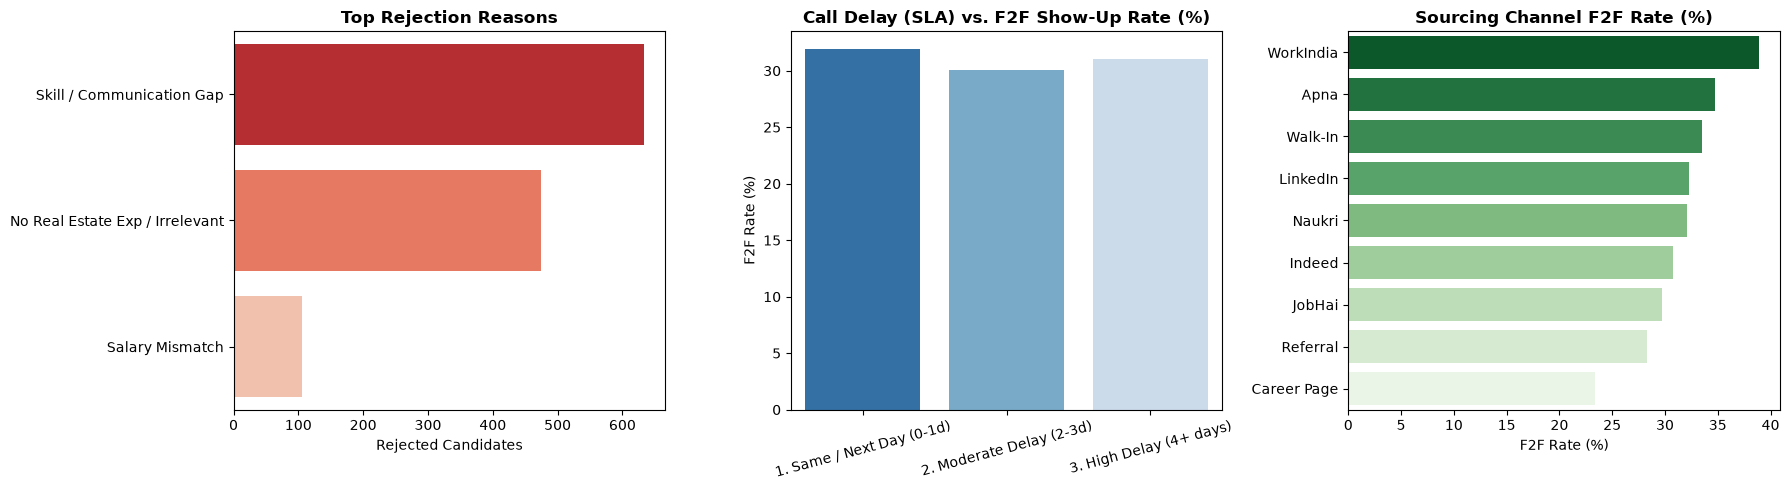

In [8]:
# Step 7: Visualize Key Hiring Bottlenecks (Rejections, SLA Delay Impact, and Source Quality)
# Purpose: Generate clean visual charts for notebook insights and portfolio documentation

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Chart 1: Top Rejection Reasons
rej_counts = df['rejection_reason'].value_counts()
sns.barplot(x=rej_counts.values, y=rej_counts.index, ax=axes[0], palette='Reds_r', hue=rej_counts.index, legend=False)
axes[0].set_title('Top Rejection Reasons', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Rejected Candidates')
axes[0].set_ylabel('')

# Chart 2: Call Delay (SLA) vs F2F Appearance Rate
sns.barplot(x=sla_summary.index, y=sla_summary['F2F_Rate (%)'], ax=axes[1], palette='Blues_r', hue=sla_summary.index, legend=False)
axes[1].set_title('Call Delay (SLA) vs. F2F Show-Up Rate (%)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('F2F Rate (%)')
axes[1].tick_params(axis='x', rotation=15)

# Chart 3: Sourcing Channel vs F2F Appearance Rate
src_sorted = source_summary.sort_values('F2F_Rate (%)', ascending=False)
sns.barplot(x=src_sorted['F2F_Rate (%)'], y=src_sorted.index, ax=axes[2], palette='Greens_r', hue=src_sorted.index, legend=False)
axes[2].set_title('Sourcing Channel F2F Rate (%)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('F2F Rate (%)')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()

In [9]:
# Step 8: Export Enriched Dataset for SQL & Power BI Dashboarding
# Purpose: Save final dataframe with engineered funnel, rejection, and SLA features

enriched_path = r"C:\Users\himsh\OneDrive\Desktop\talent-funnel-bottleneck-analytics\data\enriched_hiring_tracker.csv"
df.to_csv(enriched_path, index=False)

print("Enriched dataset saved successfully!")
print("Total rows:", len(df))
print("Columns exported:", list(df.columns))

Enriched dataset saved successfully!
Total rows: 3163
Columns exported: ['s_no', 'name', 'phone_number', 'source', 'role', 'target_market', 'contacted_by', 'applied_date', 'contacted_date', 'current_status', 'remarks', 'funnel_stage', 'rejection_reason', 'call_delay_days', 'sla_bucket', 'is_f2f_appeared', 'is_joined']
